Devolop an end to end ml regression system that predicts nightly rental Airbnb property in newyork city


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import openpyxl
import seaborn as sns

In [2]:
airbnb = pd.read_excel("AB_NYC_2019_classroom_30000.xlsx")

In [3]:
airbnb.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,100000,Entire home/apt in East Village,17749,James,Manhattan,East Village,40.79192,-73.95220,Entire home/apt,393,7,31,2016-10-06,1.45,1,217
1,100001,Entire home/apt in Fordham,27211,James,Bronx,Fordham,40.80563,-73.87973,Entire home/apt,310,4,25,2017-05-10,0.44,1,277
2,100002,Entire home/apt in Greenpoint,19702,Sarah,Brooklyn,Greenpoint,40.64088,-73.88128,Entire home/apt,240,1,29,2017-11-22,1.27,1,207
3,100003,Entire home/apt in Park Slope,39497,Lisa,Brooklyn,Park Slope,40.60449,-73.93313,Entire home/apt,197,1,29,2017-10-27,0.33,1,164
4,100004,Entire home/apt in Upper West Side,7773,Jessica,Manhattan,Upper West Side,40.71641,-73.98910,Entire home/apt,324,3,28,2019-02-28,0.42,1,171


AirBnB Dataset

id - unique id <br> name - Building name <br> host_id - Unique id for hosts <br> host_name - Name of the Host <br> neighbourhood_group - neighbourhood where the listing is situated <br> neighbourhood - Exact neighboorhood where listing is situated <br> latitude - latitude <br> longitude - longitude <br>
room_type - The type of room (Entire home/apt) <br> price - price listed <br> minimum_nights - minimum night stay requirement <br> number_of_reviews - number_of_reviews <br> last_review - last review date <br> reviews_per_month - reviews_per_month <br> calculated_host_listings_count - No of listing managed by host <br> availability_365 - Total available days

In [4]:
airbnb.describe()

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000,30000.000000,30000.000000,30000.000000
mean,114999.500000,30499.829533,40.711028,-73.952032,200.651300,3.141967,34.968800,2017-12-14 03:01:52.320000,0.902823,3.501900,182.132467
min,100000.000000,1001.000000,40.462010,-74.273060,20.000000,1.000000,12.000000,2016-06-11 00:00:00,0.000000,1.000000,0.000000
25%,107499.750000,15625.000000,40.654855,-73.997580,133.000000,1.000000,31.000000,2017-03-15 00:00:00,0.360000,1.000000,120.000000
50%,114999.500000,30467.500000,40.715915,-73.960685,191.000000,2.000000,35.000000,2017-12-17 00:00:00,0.710000,1.000000,182.000000
75%,122499.250000,45313.000000,40.762930,-73.918170,263.000000,3.000000,39.000000,2018-09-14 00:00:00,1.240000,3.000000,245.000000
max,129999.000000,59999.000000,40.948860,-73.612020,540.000000,30.000000,64.000000,2019-06-15 00:00:00,7.080000,50.000000,363.000000
std,8660.398374,17067.658207,0.068907,0.076388,92.424114,4.600621,5.891122,NaN,0.737399,7.562418,81.596375


In [5]:
airbnb.info()
airbnb.shape

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   id                              30000 non-null  int64         
 1   name                            29992 non-null  str           
 2   host_id                         30000 non-null  int64         
 3   host_name                       29988 non-null  str           
 4   neighbourhood_group             30000 non-null  str           
 5   neighbourhood                   30000 non-null  str           
 6   latitude                        30000 non-null  float64       
 7   longitude                       30000 non-null  float64       
 8   room_type                       30000 non-null  str           
 9   price                           30000 non-null  int64         
 10  minimum_nights                  30000 non-null  int64         
 11  number_of_rev

(30000, 16)

In [6]:
airbnb.isna().sum()

id                                 0
name                               8
host_id                            0
host_name                         12
neighbourhood_group                0
neighbourhood                      0
latitude                           0
longitude                          0
room_type                          0
price                              0
minimum_nights                     0
number_of_reviews                  0
last_review                        0
reviews_per_month                  0
calculated_host_listings_count     0
availability_365                   0
dtype: int64

In [7]:
airbnb.duplicated().sum()

np.int64(0)

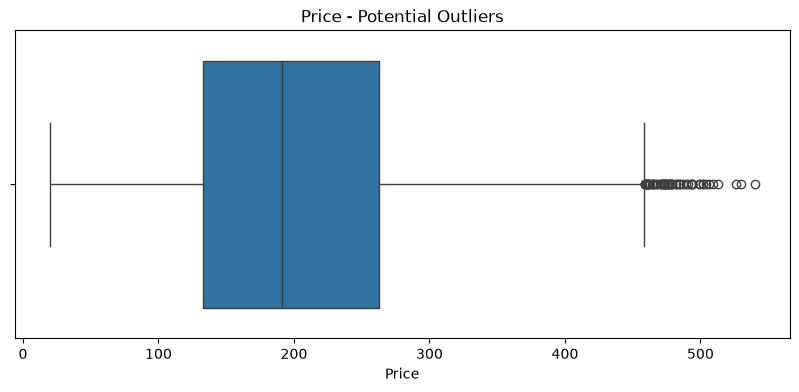

In [8]:
plt.figure(figsize=(10,4))
sns.boxplot(x=airbnb["price"])
plt.title("Price - Potential Outliers")
plt.xlabel("Price")

plt.show()

In [9]:
print("Price quantiles:")
display(airbnb["price"].quantile([0,.25,.5,.75,.9,.95,.99,1]).to_frame("price"))

Price quantiles:


,price
0.00,20.0
0.25,133.0
0.50,191.0
0.75,263.0
0.90,333.0
0.95,365.0
0.99,418.0
1.00,540.0


,count
neighbourhood_group,
Manhattan,13233
Brooklyn,12308
Queens,2659
Bronx,1208
Staten Island,592


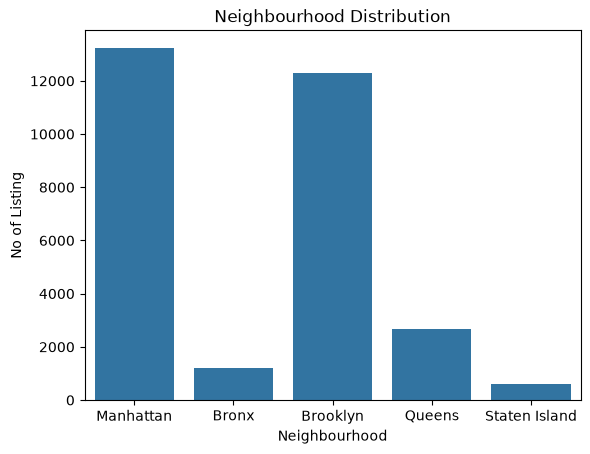

In [10]:
target_counts= airbnb["neighbourhood_group"].value_counts()
display(target_counts.to_frame("count"))

sns.countplot(data=airbnb,x="neighbourhood_group")

plt.title("Neighbourhood Distribution")
plt.xlabel("Neighbourhood")
plt.ylabel("No of Listing")

plt.show()

In [11]:
airbnb.head(1)

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,100000,Entire home/apt in East Village,17749,James,Manhattan,East Village,40.79192,-73.9522,Entire home/apt,393,7,31,2016-10-06,1.45,1,217


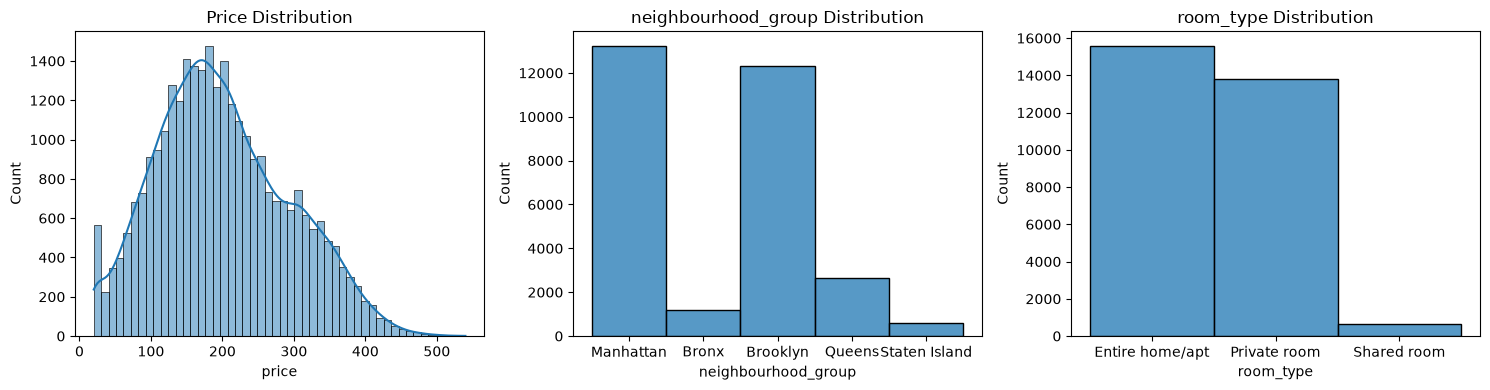

In [12]:
fig,axes=plt.subplots(1,3,figsize=(15,4))
sns.histplot(airbnb["price"],bins=50,kde=True,ax=axes[0])
axes[0].set_title("Price Distribution")

sns.histplot(airbnb["neighbourhood_group"],discrete=True,ax=axes[1])
axes[1].set_title("neighbourhood_group Distribution")

sns.histplot(airbnb["room_type"],discrete=True,ax=axes[2])
axes[2].set_title("room_type Distribution")


plt.tight_layout()
plt.show()

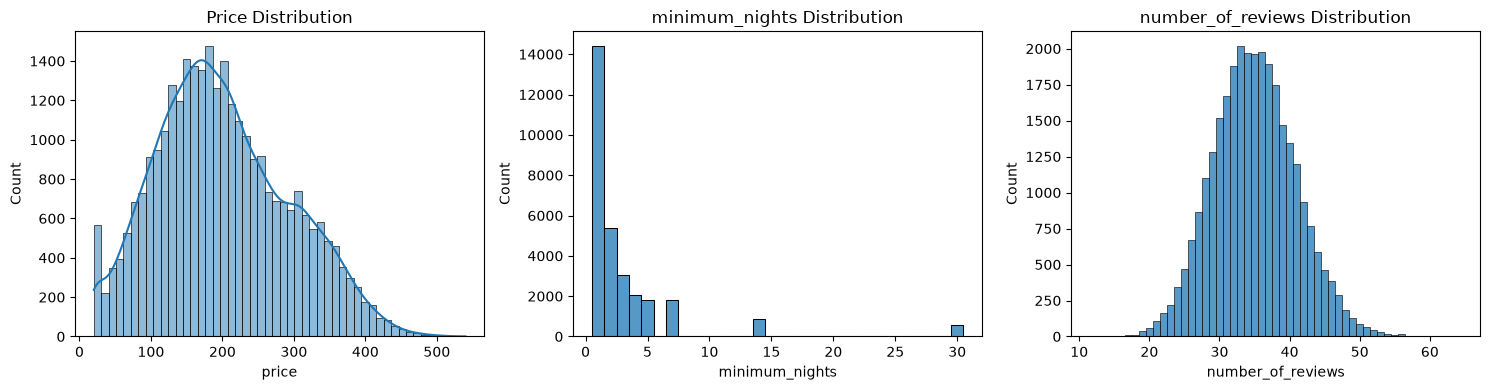

In [13]:
fig,axes=plt.subplots(1,3,figsize=(15,4))
sns.histplot(airbnb["price"],bins=50,kde=True,ax=axes[0])
axes[0].set_title("Price Distribution")

sns.histplot(airbnb["minimum_nights"],discrete=True,ax=axes[1])
axes[1].set_title("minimum_nights Distribution")

sns.histplot(airbnb["number_of_reviews"],discrete=True,ax=axes[2])
axes[2].set_title("number_of_reviews Distribution")


plt.tight_layout()
plt.show()

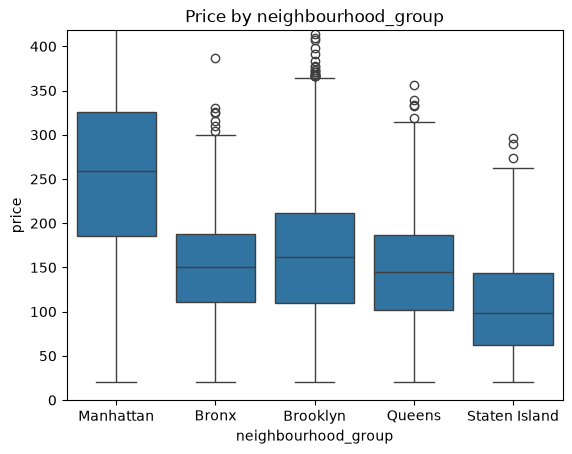

In [14]:
plt.Figure(figsize=(9,5))
sns.boxplot(
    data=airbnb,
    x="neighbourhood_group",
    y="price"
)
plt.ylim(0,airbnb["price"].quantile(.99))
plt.title("Price by neighbourhood_group")
plt.show()

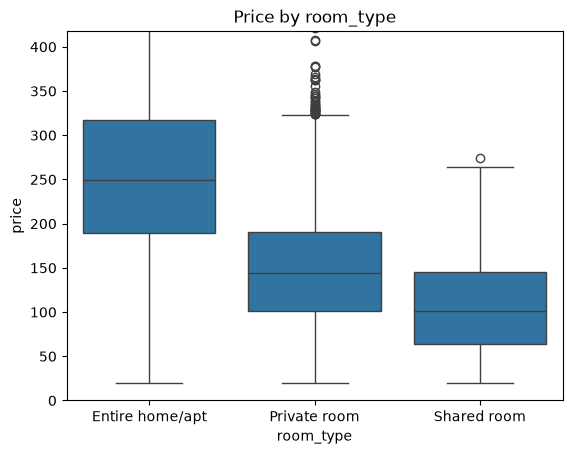

In [15]:
plt.Figure(figsize=(9,5))
sns.boxplot(
    data=airbnb,
    x="room_type",
    y="price"
)
plt.ylim(0,airbnb["price"].quantile(.99))
plt.title("Price by room_type")
plt.show()

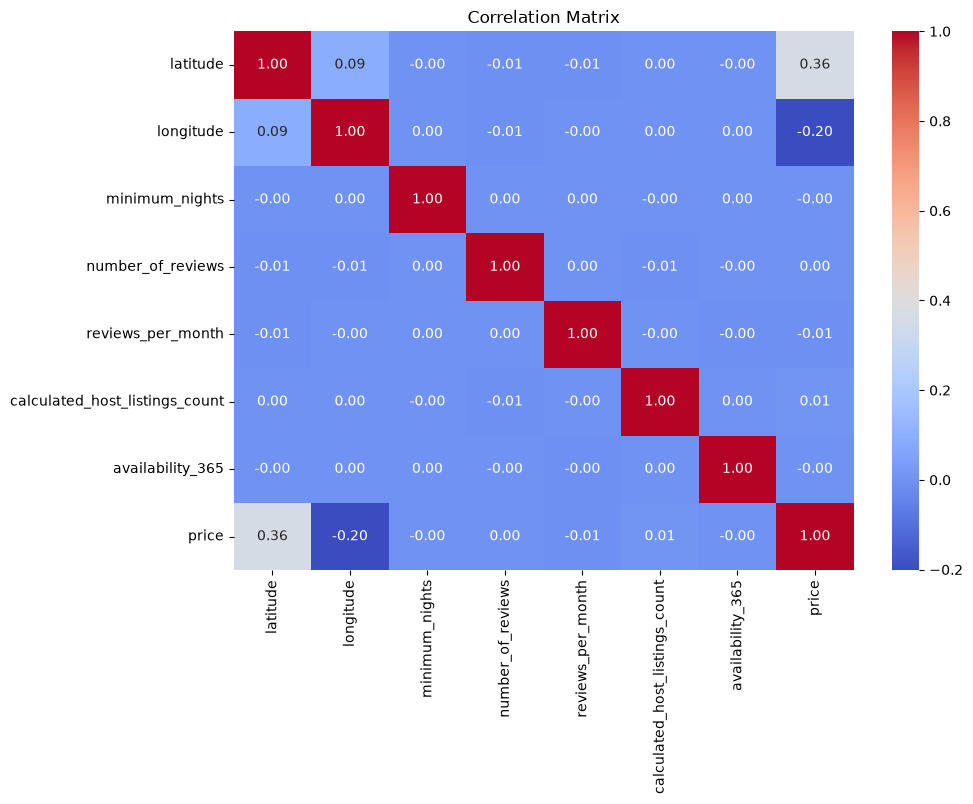

In [16]:
numeric_features = [
    "latitude",
    "longitude",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "calculated_host_listings_count",
    "availability_365",
    "price"
]

plt.figure(figsize=(10, 7))

sns.heatmap(
    airbnb[numeric_features].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Matrix")

plt.show()

In [17]:
airbnb.head(1)

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,100000,Entire home/apt in East Village,17749,James,Manhattan,East Village,40.79192,-73.9522,Entire home/apt,393,7,31,2016-10-06,1.45,1,217


In [18]:
from sklearn.model_selection import train_test_split

In [19]:
Q1 = airbnb["price"].quantile(0.25)
Q3 = airbnb["price"].quantile(0.75)
IQR = Q3 -Q1

lower =Q1 - 1.5 *IQR
upper =Q3 + 1.5 *IQR

outliers = airbnb[(airbnb["price"]<lower)|(airbnb["price"]>upper)]
print("Number of outliers:", len(outliers))

Number of outliers: 66


In [20]:
from sklearn.model_selection import train_test_split

In [21]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler


In [22]:
numeric_features = [
    'latitude',
    'longitude',
    'minimum_nights',
    'number_of_reviews',
    'reviews_per_month',
    'calculated_host_listings_count',
    'availability_365'
]
numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

print("Numerical preprocessing pipeline created")

Numerical preprocessing pipeline created


In [23]:
X_basic = airbnb[numeric_features].copy()
y = airbnb["price"].copy()
X_train, X_test, y_train, y_test = train_test_split(
    X_basic,
    y,
    test_size=.20,
    random_state=42
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (24000, 7)
Testing: (6000, 7)


In [24]:
categorical_features = [
    'neighbourhood_group',
    'room_type'
]

In [25]:
from sklearn.preprocessing import OneHotEncoder
categorical_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

print("Categorical preprocessing pipeline created")

Categorical preprocessing pipeline created


In [26]:
from sklearn.compose import ColumnTransformer

combined_preprocessor = ColumnTransformer(
    transformers=[
        ("num",numeric_preprocessor,numeric_features),
        ("cat",categorical_preprocessor,categorical_features)
    ],
    remainder="drop"
)
print("Combined numerical + categorical preprocessor created.")

Combined numerical + categorical preprocessor created.


In [27]:
X_combined = airbnb[numeric_features + categorical_features].copy()
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_combined,
    y,
    test_size=.20,
    random_state=42
)
from sklearn.linear_model import LinearRegression
linear_regression = Pipeline([
    ("preprocessing", combined_preprocessor),
    ("model", LinearRegression())
])
linear_regression.fit(X_train_c, y_train_c)
basic_pred = linear_regression.predict(X_test_c)
print("Linear Regression Trained.")

Linear Regression Trained.


In [28]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
import time
def evaluate_regression(model_name,model,X_train,X_test,y_train,y_test):
    start = time.time()
    model.fit(X_train,y_train)
    predictions = model.predict(X_test)

    result = {
        "model": model_name,
        "MAE": mean_absolute_error(y_test,predictions),
        "RMSE": mean_squared_error(y_test,predictions)**0.5,
        "R2":r2_score(y_test,predictions),
        "training_seconds": time.time() - start
    }
    return result, predictions

In [29]:
from sklearn.ensemble import RandomForestRegressor
rf_basic = Pipeline([
    ("preprocessing",numeric_preprocessor),
    ("model",RandomForestRegressor(
        n_estimators=150,
        random_state=42,
        n_jobs=1
    ))
])
rf_basic.fit(X_train,y_train)
rf_pred= rf_basic.predict(X_test)



In [30]:
from sklearn.ensemble import RandomForestRegressor
rf_combined = Pipeline([
    ("preprocessing",combined_preprocessor),
    ("model",RandomForestRegressor(
        n_estimators=150,
        random_state=42,
        n_jobs=1
    ))
])
rf_combined.fit(X_train_c,y_train_c)
rf_pred_c= rf_combined.predict(X_test_c)



In [31]:
linear_numeric = Pipeline([
    ("preprocessing", numeric_preprocessor),
    ("model", LinearRegression())
])
linear_numeric.fit(X_train, y_train)
num_pred = linear_numeric.predict(X_test)
print("Linear Regression Trained.")

Linear Regression Trained.


In [32]:
lr,lp=evaluate_regression("Random Forest Regression combined",
                          rf_combined, X_train_c, X_test_c, y_train_c, y_test_c)
rr,rp=evaluate_regression("Linear Regression combined",
                          linear_regression, X_train_c, X_test_c, y_train_c, y_test_c)
print(lr)
print(rr)
#print(evaluate_regression("Random Forest Regression numeric",
         #                 rf_basic, X_train, X_test, y_train, y_test))
#print(evaluate_regression("Linear Regression numeric",
       #                   linear_numeric, X_train, X_test, y_train, y_test))


{'model': 'Random Forest Regression combined', 'MAE': 42.14558777777778, 'RMSE': 52.9771798084029, 'R2': 0.6715687521036575, 'training_seconds': 18.19724941253662}
{'model': 'Linear Regression combined', 'MAE': 42.544160026961194, 'RMSE': 53.72467093337354, 'R2': 0.6622352464956426, 'training_seconds': 0.05176591873168945}


Random Forest Better

In [33]:
airbnb_model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression - Numeric",
        "Linear Regression - Combined",
        "Random Forest - Numeric",
        "Random Forest - Combined"
    ],
    "MAE": [
        mean_absolute_error(y_test, num_pred),
        mean_absolute_error(y_test_c, basic_pred),
        mean_absolute_error(y_test, rf_pred),
        mean_absolute_error(y_test_c, rf_pred_c)
    ],
    "RMSE": [
        mean_squared_error(y_test, num_pred) ** 0.5,
        mean_squared_error(y_test_c, basic_pred) ** 0.5,
        mean_squared_error(y_test, rf_pred) ** 0.5,
        mean_squared_error(y_test_c, rf_pred_c) ** 0.5
    ],
    "R2": [
        r2_score(y_test, num_pred),
        r2_score(y_test_c, basic_pred),
        r2_score(y_test, rf_pred),
        r2_score(y_test_c, rf_pred_c)
    ]
})

display(
    airbnb_model_comparison.sort_values(
        "R2",
        ascending=False
    )
)

,Model,MAE,RMSE,R2
3,Random Forest - Combined,42.145588,52.977180,0.671569
1,Linear Regression - Combined,42.544160,53.724671,0.662235
2,Random Forest - Numeric,66.271772,80.853281,0.234999
0,Linear Regression - Numeric,67.855047,82.817022,0.197387


In [34]:
from sklearn.dummy import DummyRegressor

In [35]:
dummy = DummyRegressor(strategy="mean")

dummy.fit(
    X_train_c,
    y_train_c
)

dummy_pred = dummy.predict(X_test_c)

print(
    "Dummy Baseline MAE:",
    round(
        mean_absolute_error(
            y_test_c,
            dummy_pred
        ),
        4
    )
)

print(
    "Dummy Baseline RMSE:",
    round(
        mean_squared_error(
            y_test_c,
            dummy_pred
        ) ** 0.5,
        4
    )
)

print(
    "Dummy Baseline R2:",
    round(
        r2_score(
            y_test_c,
            dummy_pred
        ),
        4
    )
)

Dummy Baseline MAE: 74.8167
Dummy Baseline RMSE: 92.4621
Dummy Baseline R2: -0.0004


In [36]:
from sklearn.model_selection import cross_val_score

In [37]:
cv_scores = cross_val_score(
    rf_combined,
    X_combined,
    y,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

print("Fold R2 scores:")
print(cv_scores)

print(
    "\nMean:",
    round(cv_scores.mean(), 4)
)

print(
    "Standard Deviation:",
    round(cv_scores.std(), 4)
)

Fold R2 scores:
[0.66647815 0.67298905 0.68286894 0.67357173 0.66924394]

Mean: 0.673
Standard Deviation: 0.0056


In [38]:
from sklearn.model_selection import GridSearchCV

In [39]:
rf_param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_split": [2, 5],
    "model__min_samples_leaf": [1, 2]
}

In [40]:
rf_grid = GridSearchCV(
    estimator=rf_combined,
    param_grid=rf_param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1,
    verbose=1
)
rf_grid.fit(
    X_train_c,
    y_train_c
)

Fitting 5 folds for each of 24 candidates, totalling 120 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__max_depth': [None, 10, ...], 'model__min_samples_leaf': [1, 2], 'model__min_samples_split': [2, 5], 'model__n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`

In [41]:
print("Best Random Forest parameters:")
print(rf_grid.best_params_)

print(
    "\nBest RF CV R2:"
)

print(
    round(
        rf_grid.best_score_,
        4
    )
)

Best Random Forest parameters:
{'model__max_depth': 10, 'model__min_samples_leaf': 2, 'model__min_samples_split': 5, 'model__n_estimators': 200}

Best RF CV R2:
0.6891


In [42]:
rf_tuned_pred = rf_grid.best_estimator_.predict(
    X_test_c
)

In [43]:
rf_tuned_mae = mean_absolute_error(
    y_test_c,
    rf_tuned_pred
)

rf_tuned_rmse = mean_squared_error(
    y_test_c,
    rf_tuned_pred
) ** 0.5

rf_tuned_r2 = r2_score(
    y_test_c,
    rf_tuned_pred
)
print(
    "Tuned Random Forest MAE:",
    round(rf_tuned_mae, 4)
)

print(
    "Tuned Random Forest RMSE:",
    round(rf_tuned_rmse, 4)
)

print(
    "Tuned Random Forest R2:",
    round(rf_tuned_r2, 4)
)

Tuned Random Forest MAE: 41.3516
Tuned Random Forest RMSE: 52.0804
Tuned Random Forest R2: 0.6826


In [44]:
rf_grid_results = pd.DataFrame(
    rf_grid.cv_results_
)

display(
    rf_grid_results[
        [
            "param_model__n_estimators",
            "param_model__max_depth",
            "param_model__min_samples_split",
            "param_model__min_samples_leaf",
            "mean_test_score",
            "std_test_score",
            "rank_test_score"
        ]
    ]
    .sort_values("rank_test_score")
    .head(10)
)

,param_model__n_estimators,param_model__max_depth,param_model__min_samples_split,param_model__min_samples_leaf,mean_test_score,std_test_score,rank_test_score
15,200,10,5,2,0.689125,0.004195,1
13,200,10,2,2,0.689117,0.004203,2
11,200,10,5,1,0.689094,0.004138,3
9,200,10,2,1,0.689041,0.004184,4
10,100,10,5,1,0.688684,0.004254,5
14,100,10,5,2,0.688644,0.004344,6
8,100,10,2,1,0.688616,0.004366,7
12,100,10,2,2,0.688602,0.004420,8
23,200,20,5,2,0.680614,0.004169,9
21,200,20,2,2,0.680432,0.004225,10


In [45]:
from sklearn.model_selection import RandomizedSearchCV

In [46]:
param_distributions = {
    "model__n_estimators": [100, 150, 200, 250, 300],
    "model__max_depth": [None, 10, 20, 30],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4]
}

In [47]:
random_search = RandomizedSearchCV(
    estimator=rf_combined,
    param_distributions=param_distributions,
    n_iter=8,
    cv=5,
    scoring="r2",
    n_jobs=-1,
    verbose=1,
    random_state=42
)

In [48]:
random_search.fit(
    X_train_c,
    y_train_c
)

Fitting 5 folds for each of 8 candidates, totalling 40 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__max_depth': [None, 10, ...], 'model__min_samples_leaf': [1, 2, ...], 'model__min_samples_split': [2, 5, ...], 'model__n_estimators': [100, 150, ...]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",8
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set t

In [49]:
print("Best Parameters:")
print(
    random_search.best_params_
)

print(
    "\nBest CV R2:",
    round(
        random_search.best_score_,
        4
    )
)

Best Parameters:
{'model__n_estimators': 250, 'model__min_samples_split': 5, 'model__min_samples_leaf': 2, 'model__max_depth': 10}

Best CV R2: 0.6892


In [50]:
random_pred = random_search.best_estimator_.predict(
    X_test_c
)

In [51]:
random_mae = mean_absolute_error(
    y_test_c,
    random_pred
)

random_rmse = mean_squared_error(
    y_test_c,
    random_pred
) ** 0.5

random_r2 = r2_score(
    y_test_c,
    random_pred
)
print(
    "RandomSearch Test MAE:",
    round(random_mae, 4)
)

print(
    "RandomSearch Test RMSE:",
    round(random_rmse, 4)
)

print(
    "RandomSearch Test R2:",
    round(random_r2, 4)
)

RandomSearch Test MAE: 41.3503
RandomSearch Test RMSE: 52.0792
RandomSearch Test R2: 0.6826


In [52]:
final_comparison = pd.DataFrame({
    "Model": [
        "Dummy Regressor",
        "Linear Regression - Numeric",
        "Linear Regression - Combined",
        "Random Forest - Numeric",
        "Random Forest - Combined",
        "Tuned Random Forest - GridSearch",
        "Tuned Random Forest - RandomSearch"
    ],
    "MAE": [
        mean_absolute_error(y_test_c, dummy_pred),
        mean_absolute_error(y_test, num_pred),
        mean_absolute_error(y_test_c, basic_pred),
        mean_absolute_error(y_test, rf_pred),
        mean_absolute_error(y_test_c, rf_pred_c),
        rf_tuned_mae,
        random_mae
    ],
    "RMSE": [
        mean_squared_error(y_test_c, dummy_pred) ** 0.5,
        mean_squared_error(y_test, num_pred) ** 0.5,
        mean_squared_error(y_test_c, basic_pred) ** 0.5,
        mean_squared_error(y_test, rf_pred) ** 0.5,
        mean_squared_error(y_test_c, rf_pred_c) ** 0.5,
        rf_tuned_rmse,
        random_rmse
    ],
    "R2": [
        r2_score(y_test_c, dummy_pred),
        r2_score(y_test, num_pred),
        r2_score(y_test_c, basic_pred),
        r2_score(y_test, rf_pred),
        r2_score(y_test_c, rf_pred_c),
        rf_tuned_r2,
        random_r2
    ]
})

display(
    final_comparison.sort_values(
        "R2",
        ascending=False
    )
)

,Model,MAE,RMSE,R2
6,Tuned Random Forest - RandomSearch,41.350288,52.079220,0.682608
5,Tuned Random Forest - GridSearch,41.351622,52.080422,0.682594
4,Random Forest - Combined,42.145588,52.977180,0.671569
2,Linear Regression - Combined,42.544160,53.724671,0.662235
3,Random Forest - Numeric,66.271772,80.853281,0.234999
1,Linear Regression - Numeric,67.855047,82.817022,0.197387
0,Dummy Regressor,74.816701,92.462129,-0.000448


Tuned Random Forest - RandomSearch has R2 = 0.682608 thus is the best model

In [53]:
final_model = random_search.best_estimator_

In [54]:
final_pred = final_model.predict(
    X_test_c
)

In [56]:
final_mae = mean_absolute_error(
    y_test_c,
    final_pred
)

final_rmse = mean_squared_error(
    y_test_c,
    final_pred
) ** 0.5

final_r2 = r2_score(
    y_test_c,
    final_pred
)

print("Final Model")

print(
    "MAE:",
    round(final_mae, 4)
)

print(
    "RMSE:",
    round(final_rmse, 4)
)

print(
    "R2:",
    round(final_r2, 4)
)

Final Model
MAE: 41.3503
RMSE: 52.0792
R2: 0.6826


In [57]:
shap_features = [
    'latitude',
    'longitude',
    'minimum_nights',
    'number_of_reviews',
    'reviews_per_month',
    'calculated_host_listings_count',
    'availability_365'
]

In [60]:
try:
    import shap
    

    x_shap = airbnb[shap_features].copy()
    y_shap = airbnb["price"].copy()

    Xs_train,Xs_test,ys_train,ys_test = train_test_split(
        x_shap,
        y_shap,
        test_size=0.20,
        random_state=42,
    )

    shap_imputer = SimpleImputer(
        strategy="median"
    )

    Xs_train_imp = shap_imputer.fit_transform(
        Xs_train
    )

    Xs_test_imp = shap_imputer.transform(
        Xs_test
    )

    shap_rf = RandomForestRegressor(
        n_estimators=150,
        random_state=42,
        n_jobs=-1
    )

    shap_rf.fit(
        Xs_train_imp,
        ys_train
    )

    shap_explainer = shap.TreeExplainer(
        shap_rf
    )

    shap_values = shap_explainer.shap_values(
        Xs_test_imp
    )
    print("SHAP calculation completed.")
except Exception as e:
    print("SHAP could not run:",e)

SHAP calculation completed.


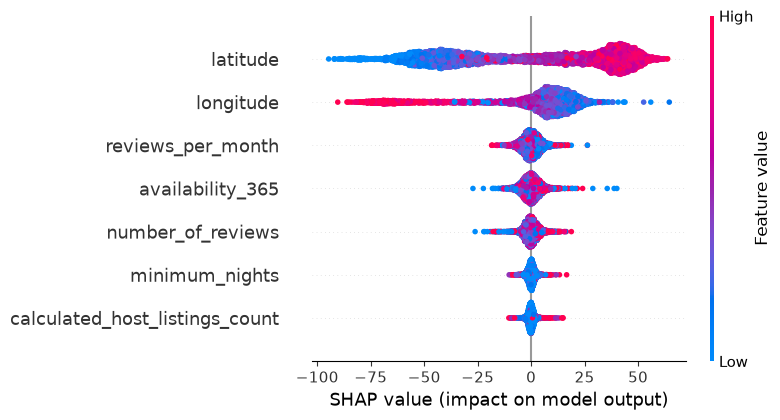

In [61]:
try:
    shap.summary_plot(
        shap_values,
        Xs_test_imp,
        feature_names = shap_features,
        show = True
    )
except Exception as e:
    print("SHAP plotting format may differ in this SHAP version.")
    print("Error:",e)

In [64]:
try:
    from lime.lime_tabular import LimeTabularExplainer
    lime_explainer = LimeTabularExplainer(
        Xs_train_imp,
        feature_names=shap_features,
        class_names=sorted(y.unique()),
        mode="regression",
        random_state=42
    )
    lime_exp = lime_explainer.explain_instance(
        Xs_test_imp[0],
        shap_rf.predict,
        num_features=8
    )
    for feature, weight in lime_exp.as_list():
        print(f"{feature}: {weight:4f}")
except Exception as e:
    print("LIME could not run:",e)

latitude > 40.76: 48.989610
longitude <= -74.00: 20.751066
120.00 < availability_365 <= 181.00: -0.999835
calculated_host_listings_count > 3.00: -0.903667
0.36 < reviews_per_month <= 0.72: 0.810022
minimum_nights <= 1.00: 0.659364
number_of_reviews > 39.00: -0.147680


In [63]:
import joblib
joblib.dump(
    final_model,
    "airbnb_final_model.joblib"
)

['airbnb_final_model.joblib']

In [65]:
loaded_model=joblib.load("airbnb_final_model.joblib")
test_predictions = loaded_model.predict(
    X_test_c.head()
)
print("Predictions from reloaded model")
print(test_predictions)

Predictions from reloaded model
[325.86608348 326.48813907 183.71234043 125.0285636  215.11086311]


In [66]:
new_listing = pd.DataFrame({

    "latitude": [40.75],

    "longitude": [-73.98],

    "minimum_nights": [1],

    "number_of_reviews": [10],

    "reviews_per_month": [2.5],

    "calculated_host_listings_count": [1],

    "availability_365": [200],

    "neighbourhood_group": ["Manhattan"],

    "room_type": ["Entire home/apt"]

})

prediction = final_model.predict(
    new_listing
)

print(
    "Predicted nightly Airbnb price: $",
    round(prediction[0], 2)
)

Predicted nightly Airbnb price: $ 325.83
